# resource_comparison — Kobayashi方式（D4 code switching）と Litinski方式（15-to-1）の資源比較

**前提**：先に `D4_switching_main`, `D4_switching_validation`, `MSD_15to1_main`, `MSD_15to1_validation` を実行して `results/` を作っておくこと。このノートは結果ファイルを読み込み、同じ計数ルールで並べる。

### このノートでの比較の約束
* 出力：両方式とも surface-code 系の論理 $T^\dagger|+\rangle$ → Pauli フレームの $\bar X$ で $T|+\rangle$（両方式コスト0、同一扱い）。
* 距離：Litinski は距離 $d$ の回転表面符号パッチ、Kobayashi は FSC の距離が $d$ となる $L=d$。
* **計数ルール R1–R3 は両方式で同一**（`common_lib`）。時間は「各符号のラウンド数」と「物理時間（下界〜上界）」を分けて示し、異なる符号のラウンドを同一視しない。
* 値の種類を区別して表示：**counted**（明示的回路から計数）、**literature**（文献値）、**assumption**（$\kappa$ など仮定パラメータに依存）、**unresolved**（未解決：除外、または例示）。

### §3.3 の限界（必ず併読）
物理誤り率0では、どちらの方式も理想入力から理想出力を得る。さらに完全な入力魔法状態が使えるなら 15-to-1 蒸留は不要である。したがってこの比較は**「ノイズのない世界での最適な $T$ ゲート実装法」を決めるものではなく**、指定した 2 つのプロトコルの回路構造と資源の比較である。`FT_ref` のラウンド数は「ノイズがあれば必要になる $d$ 依存のラウンド数」を文献の慣習（Litinski: 1τ = $d$ cycles）と仮定（Kobayashi: $\kappa d$）で与えたものであり、ノイズ下の性能（論理誤り率）は評価していない。

In [1]:
# ==== 環境設定（Google Colab / ローカル共通）====
import os, sys, subprocess, json
IN_COLAB = 'google.colab' in sys.modules
# Colab では、すべての .ipynb を同じフォルダに置き、そのフォルダを作業ディレクトリにしてください。
# 例（Google Drive を使う場合）:
#   from google.colab import drive; drive.mount('/content/drive')
#   os.chdir('/content/drive/MyDrive/D4_vs_MSD')
for _f in ['common_lib.ipynb', 'd4_lib.ipynb', 'msd_lib.ipynb']:
    if not os.path.exists(_f):
        print(f'WARNING: {_f} が作業ディレクトリ {os.getcwd()} にありません')
RESULTS, FIGURES = 'results', 'figures'
os.makedirs(RESULTS, exist_ok=True); os.makedirs(FIGURES, exist_ok=True)
SEED = 20261024
print('cwd =', os.getcwd(), '| Colab =', IN_COLAB)

cwd = /home/user/2026-10-24_StudyWithClaude | Colab = False


In [2]:
# ==== 外部ライブラリ（Colab に無いものだけをインストール）====
import importlib
for _mod, _pkg in [('stim', 'stim'), ('scipy', 'scipy'), ('sympy', 'sympy'), ('pandas', 'pandas'),
                   ('matplotlib', 'matplotlib'), ('nbformat', 'nbformat')]:
    if importlib.util.find_spec(_mod) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', _pkg], check=True)
import numpy as np, pandas as pd, scipy
print('numpy', np.__version__, '| scipy', scipy.__version__, '| pandas', pd.__version__)

numpy 2.5.3 | scipy 1.18.1 | pandas 3.0.5


In [3]:
# ==== 図のスタイル（明るい背景・細い線・識別は色＋線種＋マーカー）====
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b', 'text.color': '#0b0b0b',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.grid': True,
                     'grid.color': '#e4e3df', 'grid.linewidth': 0.8, 'lines.linewidth': 2,
                     'lines.markersize': 7, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 10, 'legend.frameon': False})
C_KOB, C_LIT, C_AUX = '#2a78d6', '#eb6834', '#1baf7a'     # categorical slots 1,2,3 (validated palette)
C_R, C_G, C_B = '#e34948', '#008300', '#2a78d6'            # colours of the r, g, b qubit species

In [4]:
need = ['d4_summary.csv', 'd4_stage_costs.csv', 'd4_blocks.json', 'msd_summary.csv', 'msd_stage_costs.csv',
        'validation_d4.json', 'validation_msd.json']
missing = [f for f in need if not os.path.exists(f'{RESULTS}/{f}')]
assert not missing, f'先に main / validation ノートを実行してください: missing {missing}'
d4s = pd.read_csv(f'{RESULTS}/d4_summary.csv'); msds = pd.read_csv(f'{RESULTS}/msd_summary.csv')
d4st = pd.read_csv(f'{RESULTS}/d4_stage_costs.csv'); msdst = pd.read_csv(f'{RESULTS}/msd_stage_costs.csv')
blocks = json.load(open(f'{RESULTS}/d4_blocks.json'))['blocks']
vd4 = json.load(open(f'{RESULTS}/validation_d4.json')); vmsd = json.load(open(f'{RESULTS}/validation_msd.json'))
D_LIST = sorted(set(d4s.d) & set(msds.d))
print('distances:', D_LIST)

distances: [3, 5, 7, 9, 11, 13, 15]


## 0. 検証状況（validation ノートの結果を読み込み）
FAIL があれば、その項目に依存する比較結果は信頼できない。未検証項目は下に列挙する。

In [5]:
rows = []
for v in (vd4, vmsd):
    res = v['results']
    rows.append(dict(notebook=v['notebook'], checks=len(res), PASS=sum(r['status'] == 'PASS' for r in res.values()),
                     FAIL=sum(r['status'] == 'FAIL' for r in res.values()), not_verified='; '.join(v['not_verified'])))
val_df = pd.DataFrame(rows); val_df

,notebook,checks,PASS,FAIL,not_verified
0,D4_switching_validation,65,65,0,Knill-Laflamme distance of the D4 phase for L>...
1,MSD_15to1_validation,31,31,0,stabilizer-level layout of the Z_m (x) Y_0 twi...


## 1. 段階別の資源コスト一覧（$d=9$、`FT_ref`、比較A、データ＋測定量子ビット、原始ゲートセット）

In [6]:
d_show = 9 if 9 in D_LIST else D_LIST[len(D_LIST) // 2]
a = d4st[(d4st.d == d_show) & (d4st.model == 'FT_ref') & (d4st.comparison == 'A') & (d4st.gateset == 'primitive') & (~d4st.data_only)]
b = msdst[(msdst.d == d_show) & (msdst.model == 'FT_ref') & (msdst.comparison == 'A') & (msdst.gateset == 'primitive') &
          (~msdst.data_only) & (msdst.level == 'physical')]
# compress Litinski's 11 identical rotations into one row (x11)
def compress(df):
    out = []; rot = df[df.stage.str.contains('auto-corrected')]; rd = df[df.stage.str.contains('readout')]
    for _, r in df.iterrows():
        if 'auto-corrected' in r.stage or 'readout' in r.stage: continue
        out.append(r.to_dict())
    for sub, name in [(rot, 'L2 auto-corrected pi/8 rotation (x11)'), (rd, 'L2b readout |0>,|m> (x11)')]:
        if len(sub):
            r = sub.iloc[0].to_dict(); r.update(stage=name, rounds=sub.rounds.sum(), time_lb=sub.time_lb.sum(), time_ub=sub.time_ub.sum())
            out.append(r)
    return pd.DataFrame(out)
tab = pd.concat([a.assign(V_qubit_round=a.qubits * a.rounds), compress(b).assign(V_qubit_round=lambda x: x.qubits * x.rounds)])
tab = tab[['protocol', 'stage', 'qubits', 'rounds', 'time_lb', 'time_ub', 'V_qubit_round', 'source']]
tab.to_csv(f'{RESULTS}/comparison_stage_table_d{d_show}.csv', index=False)
tab

,protocol,stage,qubits,rounds,time_lb,time_ub,V_qubit_round,source
312,Kobayashi_D4,S0 FSC |+_L> preparation,683,9,73.0,127,6147,assumption (parameter)
313,Kobayashi_D4,S1 switch-in (gauging) to D4,1007,9,81.0,252,9063,assumption (parameter)
314,Kobayashi_D4,S2 transversal U = W V (logical T^dag),504,0,5.0,5,0,counted (explicit circuit)
315,Kobayashi_D4,S3 switch-out: Z^g meas + S^g correction,504,0,2.0,2,0,counted (explicit circuit)
316,Kobayashi_D4,S4 FSC error-correction rounds,683,9,72.0,126,6147,assumption (parameter)
317,Kobayashi_D4,S5 logical X frame: T^dag|+> -> T|+>,0,0,0.0,0,0,counted (explicit circuit)
0,Litinski_15to1,L1 init qubit 5 |+> (step 1),1451,0,0.0,0,0,literature
1,Litinski_15to1,L3 X measurement of qubits 1-4,1451,0,1.0,1,0,literature
2,Litinski_15to1,L4 logical X frame: T^dag|+> -> T|+>,0,0,0.0,0,0,counted (explicit circuit)
3,Litinski_15to1,L2 auto-corrected pi/8 rotation (x11),1777,99,594.0,1188,175923,counted (explicit circuit)


`rounds` は Kobayashi では FSC／D4 のラウンド、Litinski では回転表面符号のラウンド。単位が違うので、横並びにする量は物理時間（`time_lb/ub`、全ゲート1単位の仮定）である。

## 2. 主比較：$d$ 依存性（`FT_ref`、比較A、データ＋測定量子ビット）

In [7]:
def pick(df, **kw):
    m = np.ones(len(df), bool)
    for k, v in kw.items(): m &= (df[k] == v).values
    return df[m].sort_values('d')
K = pick(d4s, model='FT_ref', comparison='A', gateset='primitive', data_only=False)
Lp = pick(msds, model='FT_ref', comparison='A', gateset='primitive', data_only=False, level='physical')
Lt = pick(msds, model='FT_ref', comparison='A', gateset='primitive', data_only=False, level='tile')
main = pd.DataFrame(dict(d=K.d.values,
    K_peak_qubits=K.peak_qubits.values, L_peak_qubits=Lp.peak_qubits.values,
    K_rounds=K.rounds.values, L_rounds=Lp.rounds.values,
    K_time_lb=K.time_lb.values, K_time_ub=K.time_ub.values, L_time_lb=Lp.time_lb.values, L_time_ub=Lp.time_ub.values,
    K_V_qr=K.V_qubit_round.values, L_V_qr=Lp.V_qubit_round.values, L_V_qr_tile_lit=Lt.V_qubit_round.values,
    K_V_t_lb=K.V_qubit_time_lb.values, K_V_t_ub=K.V_qubit_time_ub.values, L_V_t_lb=Lp.V_qubit_time_lb.values, L_V_t_ub=Lp.V_qubit_time_ub.values))
main['ratio_peak_qubits'] = main.K_peak_qubits / main.L_peak_qubits
main['ratio_V_qubit_round'] = main.K_V_qr / main.L_V_qr
main['ratio_V_time_lb'] = main.K_V_t_lb / main.L_V_t_lb
main['ratio_V_time_ub'] = main.K_V_t_ub / main.L_V_t_ub
main['ratio_V_time_range'] = [f'{min(x, y):.3f}–{max(x, y):.3f}' for x, y in
                              zip(main.K_V_t_lb / main.L_V_t_ub, main.K_V_t_ub / main.L_V_t_lb)]
main.to_csv(f'{RESULTS}/comparison_main_FT_ref_A.csv', index=False)
main.round(3)

,d,K_peak_qubits,L_peak_qubits,K_rounds,L_rounds,K_time_lb,K_time_ub,L_time_lb,L_time_ub,K_V_qr,...,L_V_qr_tile_lit,K_V_t_lb,K_V_t_ub,L_V_t_lb,L_V_t_ub,ratio_peak_qubits,ratio_V_qubit_round,ratio_V_time_lb,ratio_V_time_ub,ratio_V_time_range
0,3,119,193,9,33,83.0,176,210.0,408,855,...,6534,7700.0,17471,40074.0,78288,0.617,0.134,0.192,0.223,0.098–0.436
1,5,319,545,15,55,133.0,288,342.0,672,3785,...,30250,33214.0,76659,185166.0,365016,0.585,0.126,0.179,0.210,0.091–0.414
2,7,615,1073,21,77,183.0,400,474.0,936,10171,...,83006,88248.0,205239,506226.0,1001952,0.573,0.123,0.174,0.205,0.088–0.405
3,9,1007,1777,27,99,233.0,512,606.0,1200,21357,...,176418,184130.0,430091,1072950.0,2128488,0.567,0.121,0.172,0.202,0.087–0.401
4,11,1495,2657,33,121,283.0,624,738.0,1464,38687,...,322102,332188.0,778095,1955034.0,3884016,0.563,0.120,0.170,0.200,0.086–0.398
5,13,2079,3713,39,143,333.0,736,870.0,1728,63505,...,531674,543750.0,1276131,3222174.0,6407928,0.560,0.120,0.169,0.199,0.085–0.396
6,15,2759,4945,45,165,383.0,848,1002.0,1992,97155,...,816750,830144.0,1951079,4944066.0,9839616,0.558,0.119,0.168,0.198,0.084–0.395


* `ratio_V_time_lb` は両方式の下界同士、`ratio_V_time_ub` は上界同士の比。`ratio_V_time_range` は最も保守的な範囲（K下界/L上界 〜 K上界/L下界）。
* Kobayashi の値は $\kappa_0=\kappa_{in}=\kappa_{out}=1$（**仮定**）に依存する。下の §4 で $\kappa$ 依存性を示す。

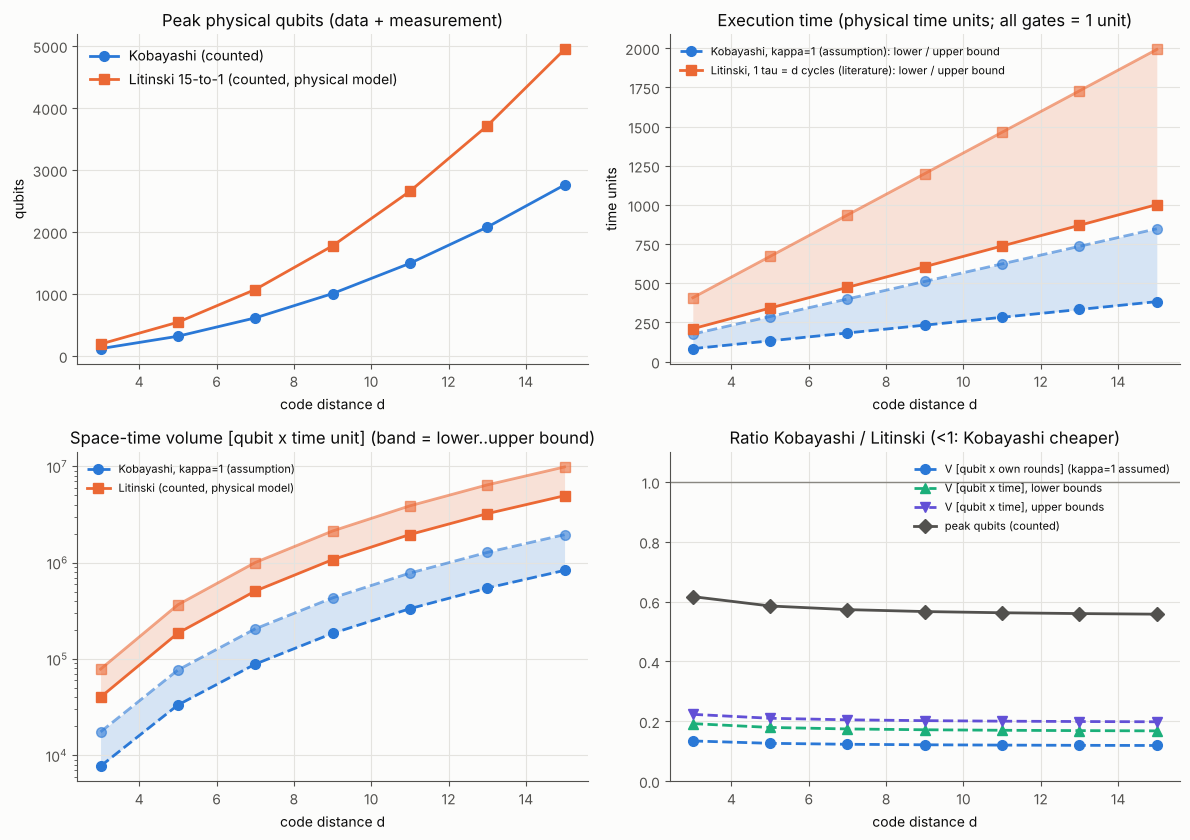

In [8]:
ds = main.d.values
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
ax = axes[0, 0]
ax.plot(ds, main.K_peak_qubits, 'o-', color=C_KOB, label='Kobayashi (counted)')
ax.plot(ds, main.L_peak_qubits, 's-', color=C_LIT, label='Litinski 15-to-1 (counted, physical model)')
ax.set_title('Peak physical qubits (data + measurement)'); ax.set_xlabel('code distance d'); ax.set_ylabel('qubits'); ax.legend()
ax = axes[0, 1]
ax.fill_between(ds, main.K_time_lb, main.K_time_ub, color=C_KOB, alpha=0.18, lw=0)
ax.plot(ds, main.K_time_lb, 'o--', color=C_KOB, label='Kobayashi, kappa=1 (assumption): lower / upper bound')
ax.plot(ds, main.K_time_ub, 'o--', color=C_KOB, alpha=0.6)
ax.fill_between(ds, main.L_time_lb, main.L_time_ub, color=C_LIT, alpha=0.18, lw=0)
ax.plot(ds, main.L_time_lb, 's-', color=C_LIT, label='Litinski, 1 tau = d cycles (literature): lower / upper bound')
ax.plot(ds, main.L_time_ub, 's-', color=C_LIT, alpha=0.6)
ax.set_title('Execution time (physical time units; all gates = 1 unit)'); ax.set_xlabel('code distance d'); ax.set_ylabel('time units'); ax.legend(fontsize=8)
ax = axes[1, 0]
ax.fill_between(ds, main.K_V_t_lb, main.K_V_t_ub, color=C_KOB, alpha=0.18, lw=0)
ax.plot(ds, main.K_V_t_lb, 'o--', color=C_KOB, label='Kobayashi, kappa=1 (assumption)')
ax.plot(ds, main.K_V_t_ub, 'o--', color=C_KOB, alpha=0.6)
ax.fill_between(ds, main.L_V_t_lb, main.L_V_t_ub, color=C_LIT, alpha=0.18, lw=0)
ax.plot(ds, main.L_V_t_lb, 's-', color=C_LIT, label='Litinski (counted, physical model)')
ax.plot(ds, main.L_V_t_ub, 's-', color=C_LIT, alpha=0.6)
ax.set_yscale('log'); ax.set_title('Space-time volume [qubit x time unit] (band = lower..upper bound)')
ax.set_xlabel('code distance d'); ax.legend(fontsize=8)
ax = axes[1, 1]
ax.plot(ds, main.ratio_V_qubit_round, 'o--', color=C_KOB, label='V [qubit x own rounds] (kappa=1 assumed)')
ax.plot(ds, main.ratio_V_time_lb, '^--', color=C_AUX, label='V [qubit x time], lower bounds')
ax.plot(ds, main.ratio_V_time_ub, 'v--', color='#6250d6', label='V [qubit x time], upper bounds')
ax.plot(ds, main.ratio_peak_qubits, 'D-', color='#52514e', label='peak qubits (counted)')
ax.axhline(1, color='#898781', lw=1)
ax.set_ylim(0, max(1.1, main[['ratio_V_qubit_round', 'ratio_V_time_lb', 'ratio_V_time_ub', 'ratio_peak_qubits']].values.max() * 1.1))
ax.set_title('Ratio Kobayashi / Litinski (<1: Kobayashi cheaper)'); ax.set_xlabel('code distance d'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIGURES}/comparison_main_FT_ref_A.png', dpi=150); plt.show()

## 3. 先頭係数（漸近的スケーリング）
計数は $d$ の多項式として厳密に同定済み（各 main ノート）。主要項のみ並べる（$\kappa=1$）。

In [9]:
pk = pd.read_csv(f'{RESULTS}/d4_polynomials.csv'); pl = pd.read_csv(f'{RESULTS}/msd_polynomials.csv')
sel_l = pl[(pl.model == 'FT_ref') & (pl.comparison == 'A') & (~pl.data_only)]
pd.concat([pk.assign(protocol='Kobayashi'), sel_l.assign(protocol='Litinski ' + sel_l.level)[['protocol', 'quantity', 'polynomial', 'exact_on_all_points']]
           .rename(columns={'polynomial': 'polynomial_in_d'})])[['protocol', 'quantity', 'polynomial_in_d', 'exact_on_all_points']]

,protocol,quantity,polynomial_in_d,exact_on_all_points
0,Kobayashi,peak qubits (D4 phase: data+anc),12*d**2 + 4*d - 1,True
1,Kobayashi,FSC qubits (data+anc),8*d**2 + 4*d - 1,True
2,Kobayashi,D4 data qubits,6*d**2 + 2*d,True
3,Kobayashi,CCZ per D4 round,6*d**2 - 12*d + 6,True
4,Kobayashi,CNOT per D4 round,24*d**2 - 6,True
5,Kobayashi,V [qubit*round] FT_ref,28*d**3 + 12*d**2 - 3*d,True
6,Kobayashi,V [qubit*time] lb FT_ref,236*d**3 + 150*d**2 - 7*d - 1,True
7,Kobayashi,V [qubit*time] ub FT_ref,560*d**3 + 274*d**2 - 38*d - 1,True
8,Kobayashi,rounds FT_ref,3*d,True
9,Kobayashi,V [qubit*round] NL_min,15*d**2 + 6*d - 1,True


まとめると（データ＋測定量子ビット、`FT_ref`、比較A）：
* Kobayashi：$V_{\rm qubit\cdot round} = (8\kappa_0+12\kappa_{in}+8\kappa_{out})d^3 + O(d^2)$ → $\kappa=1$ で $28d^3+\dots$
* Litinski：$V_{\rm qubit\cdot round} = 242d^3 - 55d$（物理モデル）、$242d^3$（tile モデル、測定量子ビット込み）、$121d^3$（tile、データのみ＝[Lit] の値）
* ピーク量子ビット：Kobayashi $12d^2+4d-1$、Litinski $22d^2-5$（物理モデル）

ただし Kobayashi の 1 ラウンド（D4 相）は物理時間で回転表面符号の 1 ラウンドより長い（上界 28 vs 12、下界 9 vs 6、全ゲート1単位）。物理時間で測った体積の比は §2 の表を参照。

## 4. $\kappa$（$O(d)$ の定数）への依存性と損益分岐
[KZH] は switch-in／EC のラウンド数を $O(d)$ としか述べていないため、$\kappa$ を振る。`d4_blocks.json` の構成要素から体積を再構成する（$\kappa=1$ で CSV と一致することを確認）。

reconstruction from blocks reproduces the CSV at kappa=1: OK


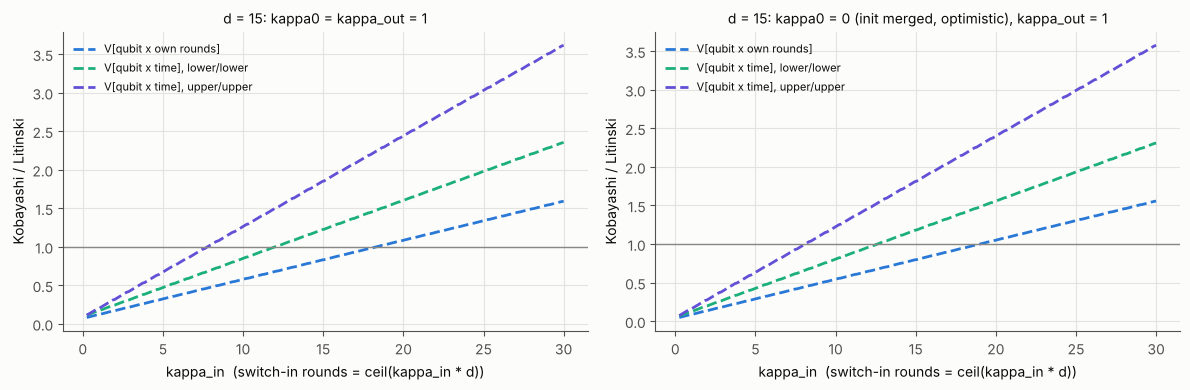

,d,kappa0,kappa_out,breakeven_kappa_in_Vqr,breakeven_kappa_in_Vtime_lb,breakeven_kappa_in_Vtime_ub
0,3,1,1,16.4,11.1,7.1
1,3,0,1,17.0,11.7,7.4
2,3,2,2,15.1,9.7,6.4
3,5,1,1,17.4,11.5,7.5
4,5,0,1,18.0,12.1,7.7
5,5,2,2,16.1,10.2,6.7
6,7,1,1,17.8,11.8,7.6
7,7,0,1,18.5,12.3,7.9
8,7,2,2,16.5,10.6,6.9
9,9,1,1,18.0,11.9,7.7


In [10]:
import math
def k_volume(d, k0, kin, kout, gs='primitive'):
    b = blocks[f'{d}|{gs}']; n = b['n']
    nf = n['fsc_data'] + n['fsc_anc']; n4 = n['d4_data'] + n['d4_anc']
    r0, r1, r4 = math.ceil(k0 * d), math.ceil(kin * d), math.ceil(kout * d)
    Rf, R4 = b['round']['FSC'], b['round']['D4']
    vqr = nf * r0 + n4 * r1 + nf * r4
    const = n['d4_data'] * (b['U_time'] + b['out_time']) + nf * b['xcorr_time']
    vlb = nf * (r0 + r4) * Rf['time_lb'] + n4 * r1 * R4['time_lb'] + const
    vub = nf * (r0 + r4) * Rf['time_ub'] + n4 * r1 * R4['time_ub'] + const
    return vqr, vlb, vub
for d in D_LIST:
    v = k_volume(d, 1, 1, 1); row = K[K.d == d].iloc[0]
    assert (v[0], v[1], v[2]) == (row.V_qubit_round, row.V_qubit_time_lb, row.V_qubit_time_ub), (d, v)
print('reconstruction from blocks reproduces the CSV at kappa=1: OK')
kins = np.linspace(0.25, 30, 240)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
dd = D_LIST[-1]
Lrow = Lp[Lp.d == dd].iloc[0]
for ax, (k0, kout, title) in zip(axes, [(1, 1, 'kappa0 = kappa_out = 1'), (0, 1, 'kappa0 = 0 (init merged, optimistic), kappa_out = 1')]):
    vs = np.array([k_volume(dd, k0, k, kout) for k in kins])
    ax.plot(kins, vs[:, 0] / Lrow.V_qubit_round, '--', color=C_KOB, label='V[qubit x own rounds]')
    ax.plot(kins, vs[:, 1] / Lrow.V_qubit_time_lb, '--', color=C_AUX, label='V[qubit x time], lower/lower')
    ax.plot(kins, vs[:, 2] / Lrow.V_qubit_time_ub, '--', color='#6250d6', label='V[qubit x time], upper/upper')
    ax.axhline(1, color='#898781', lw=1)
    ax.set_xlabel('kappa_in  (switch-in rounds = ceil(kappa_in * d))'); ax.set_ylabel('Kobayashi / Litinski')
    ax.set_title(f'd = {dd}: {title}', fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIGURES}/comparison_kappa_sweep.png', dpi=150); plt.show()
rows = []
for d in D_LIST:
    Lr = Lp[Lp.d == d].iloc[0]
    for k0, kout in [(1, 1), (0, 1), (2, 2)]:
        be = {}
        for j, key in enumerate(['V_qubit_round', 'V_qubit_time_lb', 'V_qubit_time_ub']):
            ks = [k for k in np.arange(0.1, 200, 0.1) if k_volume(d, k0, k, kout)[j] >= Lr[key]]
            be[key] = round(ks[0], 1) if ks else None
        rows.append(dict(d=d, kappa0=k0, kappa_out=kout, breakeven_kappa_in_Vqr=be['V_qubit_round'],
                         breakeven_kappa_in_Vtime_lb=be['V_qubit_time_lb'], breakeven_kappa_in_Vtime_ub=be['V_qubit_time_ub']))
be_df = pd.DataFrame(rows); be_df.to_csv(f'{RESULTS}/comparison_breakeven_kappa.csv', index=False); be_df

損益分岐 $\kappa_{in}$：これより大きい定数で switch-in に $\kappa_{in}d$ ラウンドが必要なら、Kobayashi 方式の体積が Litinski 方式（比較A、物理モデル）を上回る。主要項だけで見ると $V_{\rm qubit\cdot round}$ では $8\kappa_0+12\kappa_{in}+8\kappa_{out}=242$ より $\kappa_{in}\approx 18.8$（$\kappa_0=\kappa_{out}=1$）。物理時間の体積では D4 ラウンドの方が深いので損益分岐はより小さい（表）。

## 5. ノイズなし最小モデル（`NL_min`）
繰り返し測定を一切しない論理的最小。**耐故障性の主張ではない**（§3.3）。

In [11]:
Kn = pick(d4s, model='NL_min', comparison='A', gateset='primitive', data_only=False)
Ln = pick(msds, model='NL_min', comparison='A', gateset='primitive', data_only=False, level='physical')
nl = pd.DataFrame(dict(d=Kn.d.values, K_peak=Kn.peak_qubits.values, L_peak=Ln.peak_qubits.values,
                       K_rounds=Kn.rounds.values, L_rounds=Ln.rounds.values, K_time_lb=Kn.time_lb.values, K_time_ub=Kn.time_ub.values,
                       L_time_lb=Ln.time_lb.values, L_time_ub=Ln.time_ub.values,
                       K_V_qr=Kn.V_qubit_round.values, L_V_qr=Ln.V_qubit_round.values,
                       ratio_V_time_lb=Kn.V_qubit_time_lb.values / Ln.V_qubit_time_lb.values,
                       ratio_V_time_ub=Kn.V_qubit_time_ub.values / Ln.V_qubit_time_ub.values))
nl.to_csv(f'{RESULTS}/comparison_NL_min_A.csv', index=False); nl.round(3)

,d,K_peak,L_peak,K_rounds,L_rounds,K_time_lb,K_time_ub,L_time_lb,L_time_ub,K_V_qr,L_V_qr,ratio_V_time_lb,ratio_V_time_ub
0,3,83,193,2,11,24.0,30,78.0,144,152,2123,0.118,0.081
1,5,219,545,2,11,24.0,30,78.0,144,404,5995,0.111,0.076
2,7,419,1073,2,11,24.0,30,78.0,144,776,11803,0.108,0.074
3,9,683,1777,2,11,24.0,30,78.0,144,1268,19547,0.107,0.073
4,11,1011,2657,2,11,24.0,30,78.0,144,1880,29227,0.106,0.073
5,13,1403,3713,2,11,24.0,30,78.0,144,2612,40843,0.105,0.072
6,15,1859,4945,2,11,24.0,30,78.0,144,3464,54395,0.105,0.072


## 6. 比較B：可能な範囲での完全な資源比較

追加で計上するもの
* Litinski：$|m\rangle$ 注入 15 回（各 $t_{\rm inj}=6$ cycles、[Lit] App. A の記述；11-tile 配置では回転ごとに直列）、物理 $T$ ゲート 15 個。
* Kobayashi：物理非 Clifford ゲート（CCZ：測定ガジェット、CS/CS$^\dagger$/$T^\dagger$：$U$）。Clifford+T 分解時の T 数と、分解でラウンドが深くなる効果。
* **FSC → 通常の回転表面符号パッチ変換：未解決**。比較Bの数値は変換を含まない**下界**。参考として「1τ の格子手術（FSC＋2 tiles）」という**例示的仮定**を加えた値も別列に示す（検証された手順ではない）。

In [12]:
rows = []
for d in D_LIST:
    for gs in ['primitive', 'clifford_t']:
        k = pick(d4s, model='FT_ref', comparison='B', gateset=gs, data_only=False); k = k[k.d == d].iloc[0]
        l = pick(msds, model='FT_ref', comparison='B', gateset=gs, data_only=False, level='physical'); l = l[l.d == d].iloc[0]
        nf = blocks[f'{d}|{gs}']['n']; conv_q = nf['fsc_data'] + nf['fsc_anc'] + 4 * d * d
        rows.append(dict(d=d, gateset=gs, K_peak=k.peak_qubits, L_peak=l.peak_qubits,
                         K_time_lb=k.time_lb, K_time_ub=k.time_ub, L_time_lb=l.time_lb, L_time_ub=l.time_ub,
                         K_V_time_lb=k.V_qubit_time_lb, K_V_time_ub=k.V_qubit_time_ub,
                         L_V_time_lb=l.V_qubit_time_lb, L_V_time_ub=l.V_qubit_time_ub,
                         K_V_qr=k.V_qubit_round, K_V_qr_with_illustrative_conversion=k.V_qubit_round + conv_q * d,
                         L_V_qr=l.V_qubit_round,
                         K_nonclifford=k.nonclifford, L_nonclifford=l.nonclifford,
                         K_Tcount_if_decomposed=k.T_count_if_decomposed, L_Tcount=l.T_count_if_decomposed))
B = pd.DataFrame(rows); B.to_csv(f'{RESULTS}/comparison_B_FT_ref.csv', index=False)
B[B.gateset == 'primitive'][['d', 'K_peak', 'L_peak', 'K_V_qr', 'K_V_qr_with_illustrative_conversion', 'L_V_qr', 'K_nonclifford', 'L_nonclifford', 'K_Tcount_if_decomposed', 'L_Tcount']]

,d,K_peak,L_peak,K_V_qr,K_V_qr_with_illustrative_conversion,L_V_qr,K_nonclifford,L_nonclifford,K_Tcount_if_decomposed,L_Tcount
0,3,119,193,855,1212,17529,"{""CCZ"": 72.0, ""CS"": 9.0, ""CSDG"": 4.0, ""TDG"": 6.0}","{""T"": 15.0}",549,15
2,5,319,545,3785,5380,61871,"{""CCZ"": 480.0, ""CS"": 25.0, ""CSDG"": 16.0, ""TDG""...","{""T"": 15.0}",3493,15
4,7,615,1073,10171,14476,145621,"{""CCZ"": 1512.0, ""CS"": 49.0, ""CSDG"": 36.0, ""TDG...","{""T"": 15.0}",10853,15
6,9,1007,1777,21357,30420,280395,"{""CCZ"": 3456.0, ""CS"": 81.0, ""CSDG"": 64.0, ""TDG...","{""T"": 15.0}",24645,15
8,11,1495,2657,38687,55132,477809,"{""CCZ"": 6600.0, ""CS"": 121.0, ""CSDG"": 100.0, ""T...","{""T"": 15.0}",46885,15
10,13,2079,3713,63505,90532,749479,"{""CCZ"": 11232.0, ""CS"": 169.0, ""CSDG"": 144.0, ""...","{""T"": 15.0}",79589,15
12,15,2759,4945,97155,138540,1107021,"{""CCZ"": 17640.0, ""CS"": 225.0, ""CSDG"": 196.0, ""...","{""T"": 15.0}",124773,15


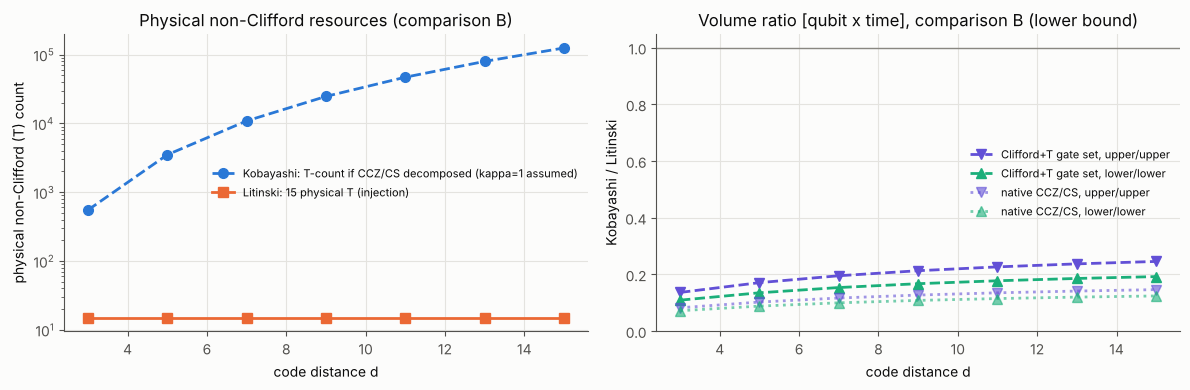

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
Bp = B[B.gateset == 'primitive']; Bc = B[B.gateset == 'clifford_t']
ax = axes[0]
ax.plot(Bp.d, Bp.K_Tcount_if_decomposed, 'o--', color=C_KOB, label='Kobayashi: T-count if CCZ/CS decomposed (kappa=1 assumed)')
ax.plot(Bp.d, Bp.L_Tcount, 's-', color=C_LIT, label='Litinski: 15 physical T (injection)')
ax.set_yscale('log'); ax.set_xlabel('code distance d'); ax.set_ylabel('physical non-Clifford (T) count')
ax.set_title('Physical non-Clifford resources (comparison B)'); ax.legend(fontsize=8)
ax = axes[1]
ax.plot(Bc.d, Bc.K_V_time_ub / Bc.L_V_time_ub, 'v--', color='#6250d6', label='Clifford+T gate set, upper/upper')
ax.plot(Bc.d, Bc.K_V_time_lb / Bc.L_V_time_lb, '^--', color=C_AUX, label='Clifford+T gate set, lower/lower')
ax.plot(Bp.d, Bp.K_V_time_ub / Bp.L_V_time_ub, 'v:', color='#6250d6', alpha=0.6, label='native CCZ/CS, upper/upper')
ax.plot(Bp.d, Bp.K_V_time_lb / Bp.L_V_time_lb, '^:', color=C_AUX, alpha=0.6, label='native CCZ/CS, lower/lower')
ax.axhline(1, color='#898781', lw=1); ax.set_ylim(0, None)
ax.set_xlabel('code distance d'); ax.set_ylabel('Kobayashi / Litinski')
ax.set_title('Volume ratio [qubit x time], comparison B (lower bound)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIGURES}/comparison_B.png', dpi=150); plt.show()

## 7. 仮定・未確定事項の一覧（表）
詳細な説明は `docs/02_assumptions_and_open_issues.md`。

In [14]:
assump = pd.DataFrame([
    ('A1', 'Kobayashi switch-in rounds = ceil(kappa_in d), kappa_in=1', 'assumption', '[KZH] states only O(d); [Dav] full text not accessible here'),
    ('A2', 'Kobayashi FSC EC rounds after return = ceil(kappa_out d), kappa_out=1', 'assumption', '[KZH] O(d)'),
    ('A3', 'FSC |+_L> preparation rounds = ceil(kappa0 d), kappa0=1', 'assumption', 'not specified in [KZH]; Litinski counts patch init as 0 tau'),
    ('A4', 'Litinski 1 tau = d code cycles', 'literature', '[Lit] Sec. 1'),
    ('A5', 'Every primitive gate / init / measurement = 1 time unit', 'assumption', 'parametrised (DUR)'),
    ('A6', 'Clifford stabilizers measured by ancilla-controlled-S (CNOT + CCZ) gadgets', 'our construction (validated)', 'circuit not given in [KZH]; V9'),
    ('A7', 'Round schedule: commuting-class upper bound / busiest-qubit lower bound', 'our construction (validated)', 'V10; optimised interleavings could be shorter'),
    ('A8', 'Frozen boundary qubits not allocated; gates on them dropped', 'counting rule', 'same rule for both codes'),
    ('A9', 'Litinski ancilla strip = 2d^2+1 qubits per tile (stim-validated increment); Z_m(x)Y_0 twist not laid out', 'approximation', 'M7'),
    ('A10', 'Injection: 3+3 cycles per |m>, serial in the 11-tile layout', 'literature', '[Lit] App. A, Sec. 3.3 Caveat'),
    ('A11', 'Classical processing / decoding latency = 0', 'assumption', 'both protocols'),
    ('U1', 'FSC -> standard rotated patch conversion', 'UNRESOLVED', 'excluded in B (lower bound); illustrative 1-tau value shown separately'),
    ('U2', 'D4-phase Knill-Laflamme distance for L >= 3', 'UNVERIFIED', 'only Z-type and X-shift distances computed'),
    ('U3', 'Fault tolerance of the switching (JIT decoder) and value of kappa', 'UNRESOLVED', 'requires noisy simulation (next stage)'),
], columns=['id', 'item', 'status', 'basis / note'])
assump.to_csv(f'{RESULTS}/assumptions_table.csv', index=False); assump

,id,item,status,basis / note
0,A1,"Kobayashi switch-in rounds = ceil(kappa_in d),...",assumption,[KZH] states only O(d); [Dav] full text not ac...
1,A2,Kobayashi FSC EC rounds after return = ceil(ka...,assumption,[KZH] O(d)
2,A3,"FSC |+_L> preparation rounds = ceil(kappa0 d),...",assumption,not specified in [KZH]; Litinski counts patch ...
3,A4,Litinski 1 tau = d code cycles,literature,[Lit] Sec. 1
4,A5,Every primitive gate / init / measurement = 1 ...,assumption,parametrised (DUR)
5,A6,Clifford stabilizers measured by ancilla-contr...,our construction (validated),circuit not given in [KZH]; V9
6,A7,Round schedule: commuting-class upper bound / ...,our construction (validated),V10; optimised interleavings could be shorter
7,A8,Frozen boundary qubits not allocated; gates on...,counting rule,same rule for both codes
8,A9,Litinski ancilla strip = 2d^2+1 qubits per til...,approximation,M7
9,A10,"Injection: 3+3 cycles per |m>, serial in the 1...",literature,"[Lit] App. A, Sec. 3.3 Caveat"


## 8. 結論（理想条件下、指定した 2 プロトコルの回路構造の比較として）

1. **正しさ**：Kobayashi 方式は、境界付き D4 符号（Fig. 4）上で $U=WV$ が論理 $T^\dagger$ を実装し、ランダムな測定結果に対する補正（$Z^rZ^b$ の Pauli フレーム補正と $S^g_X$ の CZ 補正）を含めて FSC 上に $T^\dagger|+\rangle$ を正しく生成することを、$L\le2$ の厳密シミュレーションと $L\le 8$ の局所厳密証明で確認した。Litinski 方式は 15-to-1 の論理動作・誤り検出・auto-corrected π/8・11 tiles × 11τ・$121d^3$ を再現した。
2. **量子ビット数**（計数）：ピークで Kobayashi $12d^2+4d-1$ に対し Litinski $22d^2-5$（データ＋測定量子ビット）。
3. **時間・体積**（$\kappa=1$ の仮定に依存）：Kobayashi は $3d$ ラウンド（FSC 2$d$ + D4 $d$）＋定数深さ、Litinski は $11d$ ラウンド。qubit·round 体積の主要項は $28d^3$ 対 $242d^3$。D4 ラウンドが深いことを物理時間で考慮しても Kobayashi 方式が小さい（§2 の比の範囲）。既定パラメータでの損益分岐 $\kappa_{in}$ は、qubit·round 体積で約 15〜19、物理時間体積で約 6〜13（$d=3$〜$15$、$\kappa_0,\kappa_{out}\in\{0,1,2\}$；§4 表）。すなわち switch-in に $d$ ラウンドの 1 桁倍程度までなら Kobayashi 方式の体積が小さい。
4. **比較B**：Kobayashi 方式は $\Theta(d^3)$ 個の物理 CCZ（Clifford+T 分解で $\approx 42d^3$ 個の T）を使うのに対し、Litinski 方式の物理非 Clifford 資源は T 15 個。ノイズなしでは問題にならないが、ノイズ下の比較で重要になる。また FSC→通常パッチ変換が未解決のため、比較Bの Kobayashi の値は下界である。
5. **限界**：ノイズ0では蒸留は本来不要であり、本比較は最適な T ゲート実装法を決めるものではない。$\kappa$、ゲート所要時間、変換コストは未確定で、結果はそれらに依存する。